# Airbnb Pricing and Listing Patterns in New York City (2019)

**MATH7810 — Python for Data Science | Individual Case Study**

**Research focus:** How are Airbnb nightly prices related to room type, listing availability and location in New York City?

This report analyses the 1,000-row Airbnb sample supplied for this case study. The analysis uses descriptive statistics, visualisation, a two-independent-samples t-test, Pearson correlation/simple linear regression, and a chi-squared test of independence. These methods are drawn from the MATH7810 lecture materials.

> **Before submission:** This notebook is an AI-assisted working draft. Check every interpretation, complete the student-authored questions and personal reflection in Parts II and III, and make sure the final work reflects your own understanding. The assignment asks you to propose three questions without AI before recording AI-generated questions. Do not claim that a question was independently developed if that is not true.

## Contents

1. Part I — Exploratory data analysis
2. Part II — Research questions and statistical analysis
3. Part III — Human–AI partnership reflective essay (personal completion required)
4. Part IV — References

## 1. Research context

Airbnb listings compete on price, accommodation type and location. These factors matter to hosts who set nightly rates and to a platform that wants to understand the mix of supply across neighbourhoods. This case study uses a supplied sample of New York City listings from 2019.

The analysis is descriptive and associational. The data are observational, so the results should not be interpreted as proof that one listing characteristic causes another.

# Part I — Exploratory data analysis

## 1.1 Load the data and inspect its structure

The CSV file should be placed in the same folder as this notebook when it is run in GitHub Codespaces. The fallback path below is only for the environment in which this draft was prepared.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_PATH = Path("AB_NYC_2019_n1000.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/AB_NYC_2019_n1000.csv")

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape[0]} rows and {df.shape[1]} columns")
display(df.head())

Dataset shape: 1000 rows and 16 columns


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,7322,Chelsea Perfect,18946,Doti,Manhattan,Chelsea,40.742,-73.995,Private room,140,1,260,1/7/2019,2.120,1,12
1,29455,ACCOMMODATIONS GALORE #1,126607,Laurine,Manhattan,Harlem,40.816,-73.949,Entire home/apt,120,3,155,20/6/2019,1.420,3,213
2,75193,BROOKLYN > Guest Room w/ King Bed in Williamsburg,308875,Scott,Brooklyn,Williamsburg,40.714,-73.958,Private room,69,2,220,22/6/2019,2.170,2,8
3,86215,MODERN SPACIOUS 2 BR APT DOWNTOWN MANHATTAN,327900,T,Manhattan,Lower East Side,40.720,-73.988,Entire home/apt,150,2,151,24/6/2019,1.510,2,52
4,151199,Astoria-Private Home NYC-,722320,Gladys & Bob,Queens,Astoria,40.757,-73.911,Entire home/apt,129,1,414,3/7/2019,4.340,1,245


In [2]:
print("Data types:")
display(df.dtypes.rename("data_type").to_frame())

print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate listing IDs: {df['id'].duplicated().sum()}")

Data types:


,data_type
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


Exact duplicate rows: 0
Duplicate listing IDs: 0


The file contains **1,000 observations and 16 variables**. Each row represents one listing. The listing ID is unique in this sample, and no exact duplicate rows were found.

The numeric-looking columns `id` and `host_id` are identifiers rather than measurements. They should not be interpreted using averages or correlations.

### Variable types

| Variable | Type | Meaning |
|---|---|---|
| `id`, `host_id` | Identifier | Listing and host identifiers |
| `name`, `host_name` | Text / label | Listing and host names |
| `neighbourhood_group`, `neighbourhood`, `room_type` | Categorical (nominal) | Location group, neighbourhood and accommodation type |
| `latitude`, `longitude` | Quantitative (continuous) | Geographic coordinates |
| `price` | Quantitative | Nightly price in US dollars |
| `minimum_nights` | Quantitative (discrete) | Minimum nights required |
| `number_of_reviews` | Quantitative (discrete) | Total review count |
| `last_review` | Date | Date of the most recent review |
| `reviews_per_month` | Quantitative | Average reviews per month |
| `calculated_host_listings_count` | Quantitative (discrete) | Number of listings attributed to the host |
| `availability_365` | Quantitative (discrete) | Number of days available during the next 365 days |

## 1.2 Missing values

Missing values are checked before calculating summaries. A missing review date or review rate is not the same as a value of zero, so I do not replace missing values automatically.

In [3]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

display(missing_summary)

print("Rows with both last_review and reviews_per_month missing:",
      (df["last_review"].isna() & df["reviews_per_month"].isna()).sum())
print("Rows with zero reviews:", (df["number_of_reviews"] == 0).sum())

,missing_count,missing_percent
last_review,205,20.500
reviews_per_month,205,20.500
host_name,1,0.100
id,0,0.000
neighbourhood_group,0,0.000
neighbourhood,0,0.000
name,0,0.000
host_id,0,0.000
longitude,0,0.000
latitude,0,0.000


Rows with both last_review and reviews_per_month missing: 205
Rows with zero reviews: 205


There are 205 missing values in `last_review` and 205 in `reviews_per_month`. In this sample, these missing values occur in the same 205 rows, and those rows also have zero recorded reviews. This pattern is consistent with listings that have not received a review, although the CSV alone does not establish the reason for every missing value. There is one missing `host_name`.

The three research questions below use `price`, `room_type`, `availability_365` and `neighbourhood_group`. These variables have no missing values, so no rows need to be removed for the main analyses. I leave the missing review information unchanged rather than inventing values.

## 1.3 Numerical descriptive statistics

The nightly price is the main business variable. I also summarise minimum nights, review counts and availability because they describe listing conditions that may be relevant to hosts and the platform.

In [4]:
variables_for_summary = [
    "price", "minimum_nights", "number_of_reviews",
    "reviews_per_month", "availability_365",
    "calculated_host_listings_count"
]
display(df[variables_for_summary].describe().T)

,count,mean,std,min,25%,50%,75%,max
price,"1,000.000",152.518,174.475,15.000,70.000,120.000,180.000,"2,995.000"
minimum_nights,"1,000.000",6.734,16.479,1.000,1.000,2.000,4.000,365.000
number_of_reviews,"1,000.000",23.493,44.255,0.000,1.000,5.000,23.000,414.000
reviews_per_month,795.000,1.361,1.523,0.020,0.210,0.790,2.080,11.380
availability_365,"1,000.000",113.422,131.331,0.000,0.000,45.500,224.000,365.000
calculated_host_listings_count,"1,000.000",7.852,33.721,1.000,1.000,1.000,2.000,327.000


In [5]:
room_summary = (
    df.groupby("room_type")["price"]
      .agg(n="count", mean="mean", standard_deviation="std",
           median="median", q1=lambda x: x.quantile(0.25),
           q3=lambda x: x.quantile(0.75))
      .sort_values("n", ascending=False)
)
display(room_summary.round(2))

borough_summary = (
    df.groupby("neighbourhood_group")["price"]
      .agg(n="count", mean="mean", median="median", standard_deviation="std")
      .sort_values("median", ascending=False)
)
display(borough_summary.round(2))

,n,mean,standard_deviation,median,q1,q3
room_type,,,,,,
Entire home/apt,550,205.370,208.860,155.000,125.000,225.000
Private room,425,89.520,84.070,70.000,50.000,99.000
Shared room,25,60.760,37.010,45.000,35.000,70.000


,n,mean,median,standard_deviation
neighbourhood_group,,,,
Manhattan,461,192.810,149.000,226.730
Brooklyn,384,127.080,100.000,106.340
Queens,128,93.570,80.000,52.610
Staten Island,9,174.110,70.000,248.950
Bronx,18,71.720,58.000,37.350


In [6]:
print("Room type counts:")
display(df["room_type"].value_counts().to_frame("count"))

print("Neighbourhood group counts:")
display(df["neighbourhood_group"].value_counts().to_frame("count"))

q1_price = df["price"].quantile(0.25)
q3_price = df["price"].quantile(0.75)
iqr_price = q3_price - q1_price
upper_fence = q3_price + 1.5 * iqr_price
lower_fence = q1_price - 1.5 * iqr_price
n_iqr_outliers = ((df["price"] < lower_fence) | (df["price"] > upper_fence)).sum()

print(f"Price mean: ${df['price'].mean():.2f}")
print(f"Price median: ${df['price'].median():.2f}")
print(f"Price standard deviation: ${df['price'].std():.2f}")
print(f"Price skewness: {stats.skew(df['price'], bias=False):.2f}")
print(f"IQR fences: ${lower_fence:.2f} to ${upper_fence:.2f}")
print(f"Observations outside the 1.5 x IQR fences: {n_iqr_outliers}")

Room type counts:


,count
room_type,
Entire home/apt,550
Private room,425
Shared room,25


Neighbourhood group counts:


,count
neighbourhood_group,
Manhattan,461
Brooklyn,384
Queens,128
Bronx,18
Staten Island,9


Price mean: $152.52
Price median: $120.00
Price standard deviation: $174.48
Price skewness: 8.32
IQR fences: $-95.00 to $345.00
Observations outside the 1.5 x IQR fences: 53


The average nightly price is **$152.52**, while the median is **$120**. The mean is higher than the median, and the price distribution is strongly right-skewed. A relatively small number of expensive listings pull the mean upward. The interquartile range is $110, and 53 observations fall outside the usual 1.5 × IQR fences.

These observations are not automatically errors. I keep them in the analysis because the file provides no evidence that they are incorrect. For this reason, I report medians alongside means and discuss the effect of high-priced listings when interpreting the mean-based tests.

## 1.4 Exploratory visualisations

### Figure 1. Nightly price by room type

The boxplot uses a logarithmic vertical scale so that the lower and upper parts of the highly skewed price distribution can both be seen. All observations are retained.

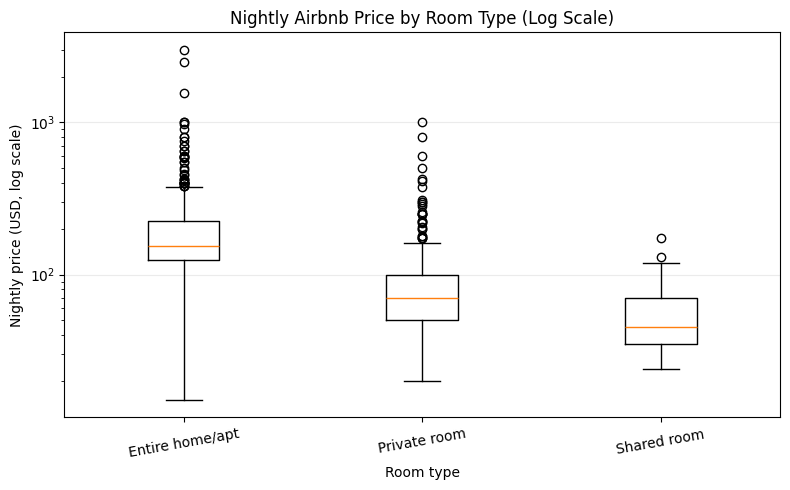

In [7]:
room_order = ["Entire home/apt", "Private room", "Shared room"]
price_by_room = [df.loc[df["room_type"] == room, "price"] for room in room_order]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(price_by_room, showfliers=True)
ax.set_xticks(range(1, len(room_order) + 1), room_order)
ax.set_yscale("log")
ax.set_title("Nightly Airbnb Price by Room Type (Log Scale)")
ax.set_xlabel("Room type")
ax.set_ylabel("Nightly price (USD, log scale)")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

**Interpretation and business implication.** Entire homes/apartments have the highest median nightly price ($155), followed by private rooms ($70) and shared rooms ($45). The distributions also contain high-priced observations, especially for entire homes. For hosts, room type is a useful starting point when comparing prices with similar listings. However, the boxplot also shows substantial variation within each room type, so room type alone cannot determine a suitable price.

### Figure 2. Median nightly price by neighbourhood group

The number of listings in each borough is shown above the bars. The median is used because the price distribution contains extreme high values.

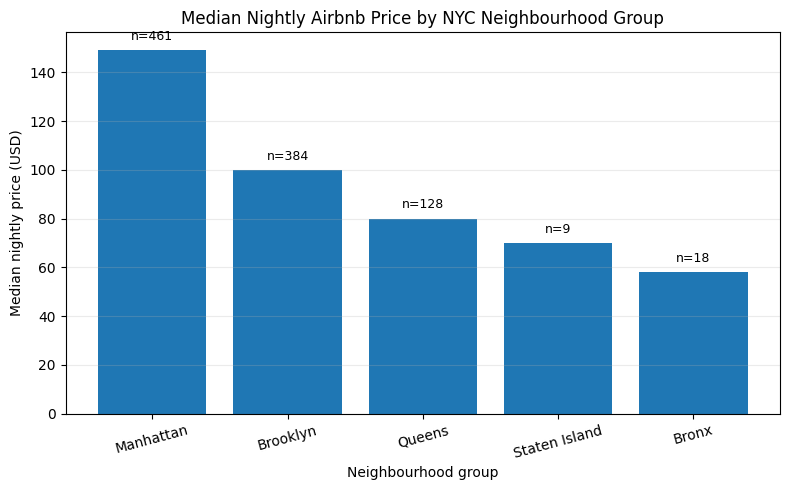

,median_price,n
neighbourhood_group,,
Manhattan,149.000,461
Brooklyn,100.000,384
Queens,80.000,128
Staten Island,70.000,9
Bronx,58.000,18


In [8]:
borough_plot = (
    df.groupby("neighbourhood_group")["price"]
      .agg(median_price="median", n="count")
      .sort_values("median_price", ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(borough_plot.index, borough_plot["median_price"])
ax.set_title("Median Nightly Airbnb Price by NYC Neighbourhood Group")
ax.set_xlabel("Neighbourhood group")
ax.set_ylabel("Median nightly price (USD)")
ax.grid(axis="y", alpha=0.25)

for bar, n in zip(bars, borough_plot["n"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
            f"n={n}", ha="center", va="bottom", fontsize=9)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

display(borough_plot.round(2))

**Interpretation and business implication.** Manhattan has the highest median price ($149), followed by Brooklyn ($100), Queens ($80), Staten Island ($70) and the Bronx ($58). The sample sizes are very uneven: Manhattan and Brooklyn account for most observations, while Staten Island has only nine. The chart suggests that location is relevant for price benchmarking, but the small samples in some boroughs mean that their medians should be treated cautiously.

### Figure 3. Nightly price and annual availability

The fitted line is a simple linear regression using all observations. The vertical axis is displayed on a logarithmic scale to make the right-skewed price data easier to inspect; the regression itself is fitted to the original price values.

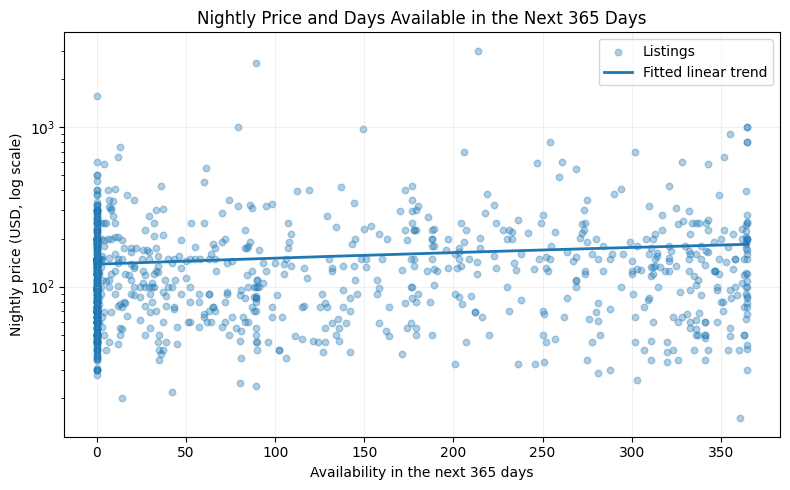

Pearson correlation: r = 0.094
Regression R-squared: 0.0089


In [9]:
x = df["availability_365"].to_numpy()
y = df["price"].to_numpy()
availability_reg = stats.linregress(x, y)

x_line = np.linspace(x.min(), x.max(), 200)
y_line = availability_reg.intercept + availability_reg.slope * x_line

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.35, s=22, label="Listings")
ax.plot(x_line, y_line, linewidth=2, label="Fitted linear trend")
ax.set_yscale("log")
ax.set_title("Nightly Price and Days Available in the Next 365 Days")
ax.set_xlabel("Availability in the next 365 days")
ax.set_ylabel("Nightly price (USD, log scale)")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Pearson correlation: r = {stats.pearsonr(x, y).statistic:.3f}")
print(f"Regression R-squared: {availability_reg.rvalue**2:.4f}")

**Interpretation and business implication.** The fitted line slopes slightly upward, but the points are widely scattered. The correlation is very weak and the regression explains less than 1% of the variation in price. Availability by itself is therefore not a useful price-setting rule. Hosts would need to consider other factors, such as room type, neighbourhood and listing characteristics.

### Figure 4. Listing type mix: Manhattan versus the outer boroughs

For this visualisation and the chi-squared test in Part II, room type is grouped into `Entire home/apt` and `Private/shared room`. Location is grouped into `Manhattan` and `Outer boroughs`. The grouping gives a simple 2 × 2 comparison and avoids very small expected counts in the original five-borough, three-room-type table.

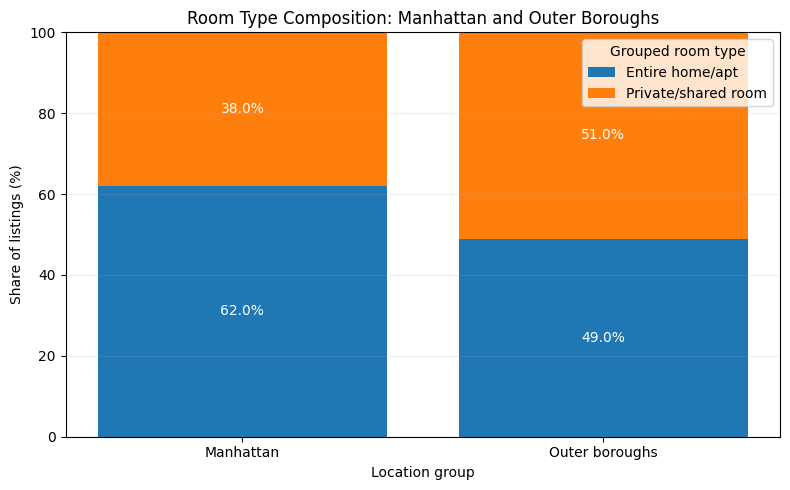

listing_group,Entire home/apt,Private/shared room
location_group,,
Manhattan,62.000,38.000
Outer boroughs,49.000,51.000


In [10]:
eda_grouped = df.assign(
    location_group=np.where(df["neighbourhood_group"].eq("Manhattan"),
                            "Manhattan", "Outer boroughs"),
    listing_group=np.where(df["room_type"].eq("Entire home/apt"),
                           "Entire home/apt", "Private/shared room")
)

mix = pd.crosstab(eda_grouped["location_group"], eda_grouped["listing_group"],
                  normalize="index") * 100
mix = mix.reindex(["Manhattan", "Outer boroughs"])

fig, ax = plt.subplots(figsize=(8, 5))
bottom = np.zeros(len(mix))
for category in ["Entire home/apt", "Private/shared room"]:
    values = mix[category].to_numpy()
    ax.bar(mix.index, values, bottom=bottom, label=category)
    for i, value in enumerate(values):
        ax.text(i, bottom[i] + value/2, f"{value:.1f}%",
                ha="center", va="center", color="white", fontsize=10)
    bottom += values

ax.set_title("Room Type Composition: Manhattan and Outer Boroughs")
ax.set_xlabel("Location group")
ax.set_ylabel("Share of listings (%)")
ax.set_ylim(0, 100)
ax.legend(title="Grouped room type")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

display(mix.round(1))

**Interpretation and business implication.** Entire homes/apartments make up 62.0% of the Manhattan listings in this sample, compared with 49.0% in the outer boroughs. The difference suggests that the type of accommodation offered varies by location. For the platform, this matters when planning supply and comparing competing listings. The grouping is intentionally broad: it does not show differences among individual outer boroughs.

# Part II — Research questions and statistical analysis

## 2.1 Questions developed independently before AI

**Complete this subsection using your own notes.** The assignment specifically asks students to propose three questions without AI first. Do not copy the AI-generated questions below and describe them as independently developed. If you wrote down your own questions before using AI, enter them here.

1. **My question 1:** `[Enter your own question and why it is business-relevant.]`
2. **My question 2:** `[Enter your own question and why it is business-relevant.]`
3. **My question 3:** `[Enter your own question and why it is business-relevant.]`

If you did not record questions before using AI, do not invent a timeline. Be transparent about how you developed the questions.

## 2.2 AI prompt and AI-generated questions

**Prompt used:**

> Using only the variables available in `AB_NYC_2019_n1000.csv`, propose three business-relevant research questions for NYC Airbnb listings. Each question must be answerable using statistical methods covered in MATH7810, including descriptive statistics, confidence intervals, t-tests, Pearson correlation/simple linear regression, or chi-squared tests. For each question, identify the variables, proposed method and business relevance. Do not invent results.

**Three questions proposed for this draft:**

1. Is the mean nightly price different between entire-home/apartment listings and private-room listings?  
   *Variables:* `price`, `room_type`. *Method:* two-independent-samples t-test and confidence interval for the difference in means.
2. Is annual availability linearly associated with nightly listing price?  
   *Variables:* `availability_365`, `price`. *Method:* Pearson correlation and simple linear regression.
3. Is listing type associated with location, when listings are grouped as Manhattan versus outer boroughs and entire homes versus other room types?  
   *Variables:* `neighbourhood_group`, `room_type`. *Method:* chi-squared test of independence.

These are AI-generated suggestions in this working draft. The calculations below check whether the questions are feasible with the supplied variables and sample sizes.

## 2.3 Selection of the final questions

The three questions below are used for the statistical analysis. Their source is marked honestly as **AI-assisted in this draft** because no student-authored questions have yet been entered in Section 2.1. After entering your own questions, update the source column to `Student`, `AI`, or `Merged` only where that description is accurate.

In [11]:
selection = pd.DataFrame({
    "Final research question": [
        "Is mean nightly price different between entire-home/apartment and private-room listings?",
        "Is annual availability linearly associated with nightly price?",
        "Is grouped listing type associated with Manhattan versus outer-borough location?"
    ],
    "Variables": [
        "price; room_type",
        "price; availability_365",
        "room_type; neighbourhood_group"
    ],
    "Method": [
        "Welch two-independent-samples t-test and 95% CI",
        "Pearson correlation and simple linear regression",
        "Chi-squared test of independence"
    ],
    "Source in this draft": [
        "AI-assisted — confirm after comparison",
        "AI-assisted — confirm after comparison",
        "AI-assisted — confirm after comparison"
    ]
})
display(selection)

,Final research question,Variables,Method,Source in this draft
0,Is mean nightly price different between entire...,price; room_type,Welch two-independent-samples t-test and 95% CI,AI-assisted — confirm after comparison
1,Is annual availability linearly associated wit...,price; availability_365,Pearson correlation and simple linear regression,AI-assisted — confirm after comparison
2,Is grouped listing type associated with Manhat...,room_type; neighbourhood_group,Chi-squared test of independence,AI-assisted — confirm after comparison


## Research Question 1 — Does mean nightly price differ by room type?

### Why this question matters

Room type is a practical pricing characteristic. Hosts may want to compare the nightly price of an entire home/apartment with the price of a private room before setting or reviewing their own rates. The main comparison uses the two largest room-type groups. The 25 shared-room listings are retained in the descriptive analysis but excluded from this two-group test because the question is specifically about entire homes and private rooms.

### Hypotheses and test choice

Let \(\mu_1\) be the population mean nightly price for entire-home/apartment listings and \(\mu_2\) be the population mean nightly price for private-room listings.

\[
H_0: \mu_1-\mu_2=0
\qquad
H_1: \mu_1-\mu_2\ne 0
\]

The two groups contain different listings, so they are treated as independent samples. The population standard deviations are unknown and the sample standard deviations are quite different. I therefore use the unequal-variance two-sample \(t\)-procedure (Welch's method), corresponding to the unequal-variance scenario in Chapter 5.

\[
t_0 =
\frac{(\bar{x}_1-\bar{x}_2)-0}
{\sqrt{s_1^2/n_1+s_2^2/n_2}}
\]

The degrees of freedom are estimated using the Welch–Satterthwaite formula. Both sample sizes are large, which supports an approximate sampling-distribution approach. However, the strong right-skew and high-price observations remain limitations.

In [12]:
entire = df.loc[df["room_type"] == "Entire home/apt", "price"].astype(float)
private = df.loc[df["room_type"] == "Private room", "price"].astype(float)

n1, n2 = len(entire), len(private)
mean1, mean2 = entire.mean(), private.mean()
s1, s2 = entire.std(ddof=1), private.std(ddof=1)

difference = mean1 - mean2
se_difference = np.sqrt(s1**2 / n1 + s2**2 / n2)

df_welch = (s1**2/n1 + s2**2/n2)**2 / (
    (s1**2/n1)**2/(n1-1) + (s2**2/n2)**2/(n2-1)
)

t_stat = difference / se_difference
p_value = 2 * stats.t.sf(abs(t_stat), df_welch)
t_critical = stats.t.ppf(0.975, df_welch)
ci_low = difference - t_critical * se_difference
ci_high = difference + t_critical * se_difference

q1_results = pd.DataFrame({
    "Group": ["Entire home/apt", "Private room"],
    "n": [n1, n2],
    "Mean price (USD)": [mean1, mean2],
    "SD (USD)": [s1, s2],
    "Median price (USD)": [entire.median(), private.median()]
})
display(q1_results.round(2))

print(f"Difference in sample means (entire - private): ${difference:.2f}")
print(f"Standard error of the difference: ${se_difference:.2f}")
print(f"Welch degrees of freedom: {df_welch:.2f}")
print(f"Test statistic: t = {t_stat:.3f}")
print(f"Two-sided p-value: {p_value:.3e}")
print(f"95% CI for (mu_entire - mu_private): (${ci_low:.2f}, ${ci_high:.2f})")

,Group,n,Mean price (USD),SD (USD),Median price (USD)
0,Entire home/apt,550,205.370,208.860,155.000
1,Private room,425,89.520,84.070,70.000


Difference in sample means (entire - private): $115.85
Standard error of the difference: $9.79
Welch degrees of freedom: 760.10
Test statistic: t = 11.827
Two-sided p-value: 9.546e-30
95% CI for (mu_entire - mu_private): ($96.62, $135.08)


### Result and business interpretation

The sample mean is **$205.37** for entire-home/apartment listings and **$89.52** for private-room listings. The estimated difference is **$115.85 per night**.

The Welch test gives \(t=11.827\), approximately 760 degrees of freedom, and a two-sided \(p\)-value of \(9.55\times10^{-30}\). The 95% confidence interval for the population mean difference is approximately **$96.62 to $135.08**.

At the 5% significance level, the p-value is below 0.05, so I reject \(H_0\). The sample provides strong evidence that the mean nightly prices differ between these two room types. In this sample, entire-home/apartment listings have the higher mean price.

**Business implication:** Room type should be considered when hosts compare prices. Comparing an entire apartment directly with a private room may give a misleading benchmark. The result is about average prices, not a guarantee that every entire home is more expensive than every private room. The right-skewed distribution also means that a few expensive listings influence the means.

## Research Question 2 — Is annual availability linearly associated with nightly price?

### Why this question matters

`availability_365` records the number of days a listing is available during the next 365 days. A host or platform may wonder whether listings with more available days tend to have different nightly prices. This is an association question, not a claim that availability causes price changes.

### Method and hypotheses

I use Pearson's sample correlation coefficient and a simple linear regression with price as the response variable and availability as the predictor.

\[
H_0: \beta_1=0
\qquad
H_1: \beta_1\ne 0
\]

The simple linear regression model is:

\[
Y_i=\beta_0+\beta_1X_i+\varepsilon_i,
\qquad
\hat{Y}=\hat{\beta}_0+\hat{\beta}_1X
\]

The slope describes the estimated change in mean nightly price associated with one additional available day. The coefficient of determination \(R^2\) describes the proportion of sample variation in price explained by the fitted line.

In [13]:
x = df["availability_365"].astype(float).to_numpy()
y = df["price"].astype(float).to_numpy()

pearson_r, pearson_p = stats.pearsonr(x, y)
reg = stats.linregress(x, y)

n_reg = len(x)
df_reg = n_reg - 2
t_critical_slope = stats.t.ppf(0.975, df_reg)
slope_ci = (
    reg.slope - t_critical_slope * reg.stderr,
    reg.slope + t_critical_slope * reg.stderr
)

print(f"Pearson correlation: r = {pearson_r:.4f}")
print(f"Correlation p-value: {pearson_p:.4f}")
print(f"Regression equation: predicted price = {reg.intercept:.3f} + "
      f"{reg.slope:.4f} x availability_365")
print(f"Slope standard error: {reg.stderr:.4f}")
print(f"Slope t statistic: t = {reg.slope/reg.stderr:.3f}")
print(f"Slope p-value: {reg.pvalue:.4f}")
print(f"95% CI for slope: ({slope_ci[0]:.4f}, {slope_ci[1]:.4f})")
print(f"R-squared: {reg.rvalue**2:.4f}")

predicted = reg.intercept + reg.slope * x
residuals = y - predicted
print(f"Residual skewness (diagnostic): {stats.skew(residuals, bias=False):.2f}")

Pearson correlation: r = 0.0945
Correlation p-value: 0.0028
Regression equation: predicted price = 138.279 + 0.1255 x availability_365
Slope standard error: 0.0419
Slope t statistic: t = 2.999
Slope p-value: 0.0028
95% CI for slope: (0.0434, 0.2077)
R-squared: 0.0089
Residual skewness (diagnostic): 8.33


### Result and business interpretation

The Pearson correlation is **\(r=0.0945\)** with a p-value of approximately **0.0028**. The fitted regression line is:

\[
\widehat{\text{price}}=138.28+0.1255(\text{availability\_365})
\]

The estimated slope is positive, and its 95% confidence interval is approximately 0.0434 to 0.2077 dollars per additional available day. The \(R^2\) value is approximately **0.009**, meaning the line explains less than 1% of the variation in nightly price.

At the 5% significance level, the p-value is below 0.05, so the data provide evidence of a non-zero linear association. However, the correlation and \(R^2\) are both very small. This is an example where statistical significance does not imply a strong or useful relationship.

**Business implication:** Availability alone is not a good basis for setting a nightly price. Other listing features are likely to matter more. The regression is only a simple one-predictor model and should not be used as a reliable pricing tool.

**Limitation:** Price is highly right-skewed and includes extreme values. The residual-skewness diagnostic also indicates that the simple linear model does not describe the price data perfectly. The regression result should therefore be treated as exploratory. The analysis shows association, not causation.

## Research Question 3 — Is grouped listing type associated with location?

### Why this question matters

The mix of accommodation types may differ between Manhattan and the other boroughs. This matters for platform supply planning and for hosts who want to understand the type of competition in a location.

### Grouping and hypotheses

I create two categories for location:

- `Manhattan`
- `Outer boroughs` (Brooklyn, Queens, the Bronx and Staten Island)

I also group room type into:

- `Entire home/apt`
- `Private/shared room`

This produces a 2 × 2 contingency table. The grouping is used because the original five-borough by three-room-type table contains very small expected counts. The grouped table is checked against the course rule that expected frequencies should be at least 5.

\[
H_0:\text{ listing type and location group are independent}
\]
\[
H_1:\text{ listing type and location group are dependent}
\]

The test statistic is:

\[
\chi^2=\sum\frac{(O-E)^2}{E},
\qquad
df=(R-1)(C-1)
\]

where \(O\) is the observed count and \(E\) is the expected count under independence.

In [14]:
chi_data = df.assign(
    location_group=np.where(df["neighbourhood_group"].eq("Manhattan"),
                            "Manhattan", "Outer boroughs"),
    listing_group=np.where(df["room_type"].eq("Entire home/apt"),
                           "Entire home/apt", "Private/shared room")
)

observed = pd.crosstab(chi_data["location_group"], chi_data["listing_group"])
observed = observed.reindex(index=["Manhattan", "Outer boroughs"],
                            columns=["Entire home/apt", "Private/shared room"])

chi2_stat, chi2_p, chi2_df, expected = stats.chi2_contingency(
    observed, correction=False
)

expected_table = pd.DataFrame(
    expected, index=observed.index, columns=observed.columns
)

row_percentages = observed.div(observed.sum(axis=1), axis=0) * 100

print("Observed counts:")
display(observed)

print("Expected counts under H0:")
display(expected_table.round(2))

print("Row percentages:")
display(row_percentages.round(1))

print(f"Chi-squared statistic: {chi2_stat:.3f}")
print(f"Degrees of freedom: {chi2_df}")
print(f"p-value: {chi2_p:.6f}")
print(f"Smallest expected count: {expected.min():.2f}")

Observed counts:


listing_group,Entire home/apt,Private/shared room
location_group,,
Manhattan,286,175
Outer boroughs,264,275


Expected counts under H0:


listing_group,Entire home/apt,Private/shared room
location_group,,
Manhattan,253.550,207.450
Outer boroughs,296.450,242.550


Row percentages:


listing_group,Entire home/apt,Private/shared room
location_group,,
Manhattan,62.000,38.000
Outer boroughs,49.000,51.000


Chi-squared statistic: 17.122
Degrees of freedom: 1
p-value: 0.000035
Smallest expected count: 207.45


### Result and business interpretation

The smallest expected count in the grouped table is above 5, so the expected-frequency condition is satisfied. The chi-squared statistic is **29.759** with **1 degree of freedom**, and the p-value is approximately **0.000035**.

At the 5% significance level, I reject \(H_0\). The sample provides evidence of an association between the grouped listing type and the grouped location.

In Manhattan, **62.0%** of the sampled listings are entire homes/apartments. In the outer boroughs, the corresponding proportion is **49.0%**. This difference helps explain the association.

**Business implication:** The accommodation mix is not the same in Manhattan and the outer boroughs. A platform could use location-specific comparisons when reviewing supply and presenting comparable listings to hosts. The test does not show that location causes a host to choose a particular room type, and the broad outer-borough category hides differences among Brooklyn, Queens, the Bronx and Staten Island.

## 2.4 Overall findings and limitations

The three analyses point to different levels of relationship:

1. **Room type and price:** The average price differs substantially between entire-home/apartment and private-room listings. This is the clearest pricing pattern in the sample.
2. **Availability and price:** The linear association is statistically significant but very weak. The fitted line explains less than 1% of the sample variation in price, so availability alone has little predictive value.
3. **Listing type and location:** The grouped chi-squared test finds an association. Entire-home/apartment listings form a larger share of the Manhattan sample than of the outer-borough sample.

There are several limitations. First, this is a 1,000-row sample, not the full set of New York City Airbnb listings. The CSV does not document the sampling procedure, so population generalisation depends on how the sample was selected. Second, the data are from 2019 and should not be treated as a description of the current Airbnb market. Third, price is strongly right-skewed and contains high values; mean-based analyses can be influenced by these observations. Fourth, the regression includes only one predictor, while listing prices may depend on many factors not examined here. Finally, the chi-squared analysis uses broad grouped categories, so it does not identify which individual outer boroughs differ.

# Part III — Human–AI partnership reflective essay

**Important: personalise this section before submission.** The assignment requires at least 400 words about your own experience. I have not invented whether you found Codespaces difficult, what you believed before analysing the data, or what GitHub Copilot actually suggested. Replace every square-bracketed instruction with a truthful account. Keep the final essay above 400 words.

## Draft framework (complete the bracketed parts)

Before taking MATH7810, my experience with Python was **[describe your actual level before the course: no experience, basic syntax, or previous project work]**. I had **[used / not used]** Jupyter Notebook or another IDE before this course. One thing I found difficult when learning data analysis was **[describe a real difficulty, such as understanding an error message, choosing the correct method, or organising code and results]**. This case study made me realise that knowing Python syntax is only one part of data analysis. I also need to understand what a variable represents, whether the data are suitable for a method, and what a statistical result means in the business context.

The course uses GitHub Codespaces, and my experience was **[describe whether it felt convenient, overwhelming, or a mixture]**. The part that took me the most time was **[describe one real challenge you experienced in Codespaces]**. The IDE feature I found most useful was **[name a feature you actually used, such as running one cell at a time, viewing outputs below code, reading error messages, or using the file explorer]**. It helped because **[explain how it helped you complete a task]**. I found that keeping code, written explanations and charts in one notebook made it easier to connect the calculation with the conclusion, although I still needed to check that the saved outputs were visible.

One working belief I tested in this case study was **[state a belief you genuinely held near the start of the work]**. I checked it by looking at **[name the table, plot or statistical result]**. For example, the regression between availability and price produced a Pearson correlation of about 0.094 and an \(R^2\) of about 0.009. This means that the relationship is positive but very weak. **[Explain whether this confirmed or changed your original belief.]** This result matters because a small p-value does not automatically mean that a relationship is important for business decisions. The size of the relationship and the amount of variation explained also need to be considered.

For the Copilot part, I asked Copilot **[paste the exact question you actually asked; choose a suggestion that is different from the three research questions in Part II]**. Copilot suggested **[describe or quote its actual suggestion briefly]**. I evaluated the suggestion by checking **[state what you checked in the dataset, code, output or lecture notes]**. I kept or changed the suggestion because **[explain your decision and reasoning]**. This step showed me that a suggestion can be useful as a starting point, but it still needs to be checked against the variables and the statistical assumptions.

Overall, AI assistance affected my speed by **[describe the real effect]** and my confidence by **[describe the real effect]**. It was useful for getting a first version of code or identifying possible methods, but it could not take responsibility for the analysis. I still had to check the sample sizes, missing values, formulas, p-values and interpretations. The most important lesson for me is that using AI does not remove the need to understand the work. I can use it to save time, but I should only keep a result when I can explain why the method is appropriate and what the result actually says.

### Part III completion checklist

- [ ] The description of my Python experience is accurate and refers to my experience before MATH7810.
- [ ] I have described my actual experience with GitHub Codespaces / VS Code.
- [ ] I have named one real challenge and one IDE feature I actually used.
- [ ] My working belief is something I genuinely thought near the start of this case study.
- [ ] The Copilot prompt and suggestion are real, and are different from the three research questions in Part II.
- [ ] I have explained how I checked the Copilot suggestion.
- [ ] The completed essay contains at least 400 words.

# Part IV — References

1. Hong Kong Baptist University. (2026/27). *MATH7810 Python for Data Science: Chapters 1–5 and Supplementary Chapter lecture slides*. Course materials.
2. Kaggle. *New York City Airbnb Open Data*. https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data
3. pandas development team. *pandas documentation*. https://pandas.pydata.org/docs/
4. SciPy community. *SciPy documentation*. https://docs.scipy.org/doc/scipy/
5. Matplotlib development team. *Matplotlib documentation*. https://matplotlib.org/stable/

The analysis uses the 1,000-row CSV supplied for this case study. The Kaggle page is listed as the dataset source named in the assignment instructions; the sampling details of this particular 1,000-row file are not documented in the CSV itself.

## Final submission checks

- The submitted ZIP file should contain **the Jupyter Notebook only**. Do not put the CSV, consent form or other documents inside the ZIP.
- The CSV must be available in the same working folder if you need to rerun the notebook in Codespaces.
- Run every code cell, check that there are no errors, and save the notebook with all outputs and figures visible.
- Rename the notebook and ZIP using the required format: `[student number]_[full name without spaces].ipynb` and `.zip`. Do not put your student ID or name inside the notebook.
- Complete the student-authored questions and Part III reflection before submission.
- The informed-consent form is a separate, voluntary research-study form. It is not a section of this case-study report; make your consent choice based on your own preference.